In [188]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [189]:
df = pd.read_csv('../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.head()

,customer_id,gender,senior_citizen,partner,dependents,phone_service,multiple_lines,internet_service,online_security,online_backup,device_protection,contract,monthly_charges,churn
0,1,Male,0,Yes,No,Yes,No,DSL,No,Yes,No,Month-to-month,29.85,Yes
1,2,Female,0,No,No,No,Yes,Fiber optic,Yes,No,Yes,Month-to-month,70.70,Yes
2,3,Female,0,No,No,No,Yes,Fiber optic,Yes,No,Yes,Month-to-month,99.65,Yes
3,4,Female,0,No,No,No,Yes,Fiber optic,Yes,Yes,Yes,Month-to-month,89.10,Yes
4,5,Male,0,Yes,No,Yes,No,DSL,Yes,No,No,Two year,56.95,No


In [190]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_id        120 non-null    int64  
 1   gender             120 non-null    str    
 2   senior_citizen     120 non-null    int64  
 3   partner            120 non-null    str    
 4   dependents         120 non-null    str    
 5   phone_service      120 non-null    str    
 6   multiple_lines     120 non-null    str    
 7   internet_service   120 non-null    str    
 8   online_security    120 non-null    str    
 9   online_backup      120 non-null    str    
 10  device_protection  120 non-null    str    
 11  contract           120 non-null    str    
 12  monthly_charges    120 non-null    float64
 13  churn              120 non-null    str    
dtypes: float64(1), int64(2), str(11)
memory usage: 13.3 KB


In [191]:
df.shape

(120, 14)

In [192]:
df.describe()

,customer_id,senior_citizen,monthly_charges
count,120.000000,120.000000,120.000000
mean,60.500000,0.075000,66.579583
std,34.785054,0.264496,24.613842
min,1.000000,0.000000,25.000000
25%,30.750000,0.000000,44.000000
50%,60.500000,0.000000,67.050000
75%,90.250000,0.000000,89.025000
max,120.000000,1.000000,111.800000


In [193]:
df.isna().sum()

customer_id          0
gender               0
senior_citizen       0
partner              0
dependents           0
phone_service        0
multiple_lines       0
internet_service     0
online_security      0
online_backup        0
device_protection    0
contract             0
monthly_charges      0
churn                0
dtype: int64

In [194]:
df['churn'].value_counts()

churn
No     85
Yes    35
Name: count, dtype: int64

In [195]:
df.groupby(['churn'])['monthly_charges'].mean()

churn
No     61.231765
Yes    79.567143
Name: monthly_charges, dtype: float64

In [196]:
df['contract'].unique()

<StringArray>
['Month-to-month', 'Two year', 'One year']
Length: 3, dtype: str

In [197]:
df.groupby(['contract'])['churn'].value_counts()

contract        churn
Month-to-month  Yes      26
                No       20
One year        No       28
                Yes       8
Two year        No       37
                Yes       1
Name: count, dtype: int64

In [198]:
df.groupby('contract')['churn'].value_counts(normalize=True)

contract        churn
Month-to-month  Yes      0.565217
                No       0.434783
One year        No       0.777778
                Yes      0.222222
Two year        No       0.973684
                Yes      0.026316
Name: proportion, dtype: float64

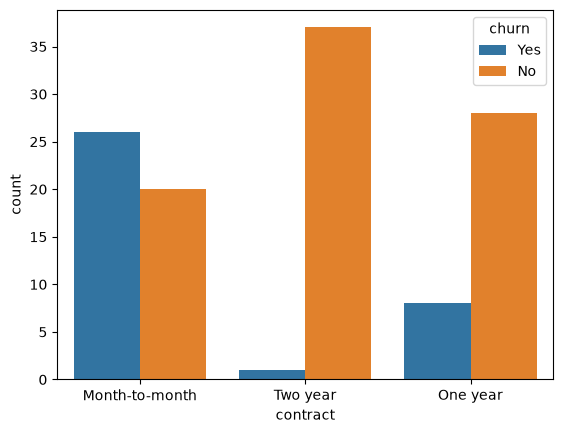

In [199]:
sns.countplot(data=df, x = 'contract', hue='churn' )
plt.show()

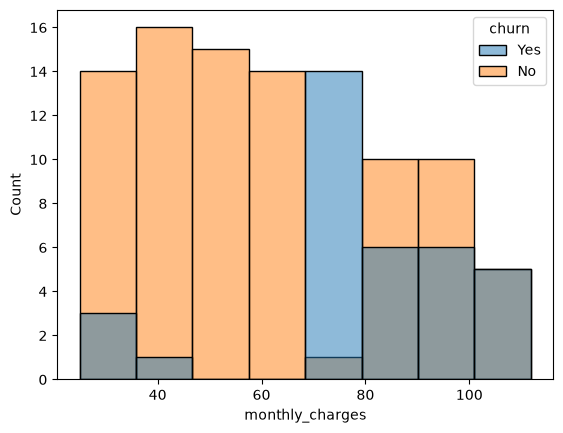

In [200]:
sns.histplot(data=df, x='monthly_charges', hue='churn')
plt.show()

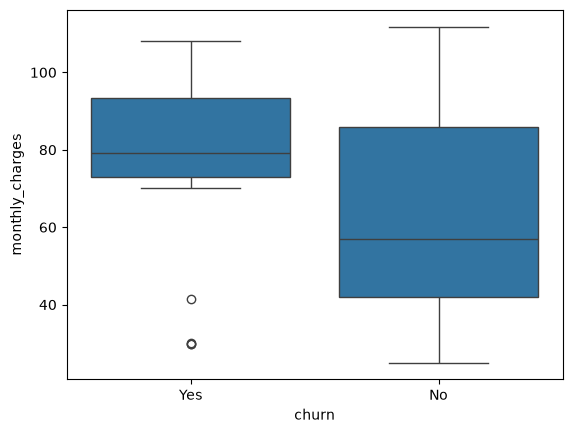

In [201]:
sns.boxplot(
    data=df,
    x='churn',
    y='monthly_charges'
)

plt.show()

In [202]:
df.head()

,customer_id,gender,senior_citizen,partner,dependents,phone_service,multiple_lines,internet_service,online_security,online_backup,device_protection,contract,monthly_charges,churn
0,1,Male,0,Yes,No,Yes,No,DSL,No,Yes,No,Month-to-month,29.85,Yes
1,2,Female,0,No,No,No,Yes,Fiber optic,Yes,No,Yes,Month-to-month,70.70,Yes
2,3,Female,0,No,No,No,Yes,Fiber optic,Yes,No,Yes,Month-to-month,99.65,Yes
3,4,Female,0,No,No,No,Yes,Fiber optic,Yes,Yes,Yes,Month-to-month,89.10,Yes
4,5,Male,0,Yes,No,Yes,No,DSL,Yes,No,No,Two year,56.95,No


## Data preprocessing


In [203]:
X = df.drop(columns=['churn', 'customer_id'])
y = df['churn']
print(X.shape)
print(y.shape)

(120, 12)
(120,)


In [204]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(96, 12)
(24, 12)
(96,)
(24,)


In [205]:
print(y.value_counts(normalize=True))
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

churn
No     0.708333
Yes    0.291667
Name: proportion, dtype: float64
churn
No     0.708333
Yes    0.291667
Name: proportion, dtype: float64
churn
No     0.708333
Yes    0.291667
Name: proportion, dtype: float64


In [206]:
X_train.head()

,gender,senior_citizen,partner,dependents,phone_service,multiple_lines,internet_service,online_security,online_backup,device_protection,contract,monthly_charges
84,Male,0,No,Yes,Yes,No,Fiber optic,No,Yes,No,One year,95.3
12,Female,0,No,No,No,Yes,Fiber optic,Yes,Yes,Yes,Month-to-month,89.5
114,Male,0,No,Yes,Yes,No,Fiber optic,No,Yes,No,One year,102.9
118,Male,0,No,No,No,No,No,No,No,No,Two year,28.8
79,Female,0,No,Yes,Yes,Yes,No,No,No,No,Two year,35.8


In [207]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(sparse_output=False)
contract_encoded = encoder.fit_transform(
    X_train[['contract']]
)
print(encoder.get_feature_names_out())
print(contract_encoded[:5])

['contract_Month-to-month' 'contract_One year' 'contract_Two year']
[[0. 1. 0.]
 [1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]
 [0. 0. 1.]]


In [208]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_features = [
    'gender',
    'senior_citizen',
    'partner',
    'dependents',
    'phone_service',
    'multiple_lines',
    'internet_service',
    'online_security',
    'online_backup',
    'device_protection',
    'contract'
]
numeric_features = [
    'monthly_charges'
]

preprocessor = ColumnTransformer(
    transformers = [
        (
            'cat', OneHotEncoder(handle_unknown='ignore'), categorical_features
        ),
        (
            'num', StandardScaler(), numeric_features
        )
    ],
)

In [209]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print(X_train.shape)
print(X_train_processed.shape)

print(X_test.shape)
print(X_test_processed.shape)

(96, 12)
(96, 25)
(24, 12)
(24, 25)


In [210]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(X_train_processed, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [211]:
y_pred = model.predict(X_test_processed)
print(y_pred)
print(y_test.values)

['No' 'No' 'No' 'Yes' 'Yes' 'No' 'Yes' 'No' 'No' 'Yes' 'No' 'Yes' 'Yes'
 'No' 'No' 'No' 'Yes' 'No' 'No' 'No' 'Yes' 'No' 'No' 'No']
<StringArray>
[ 'No',  'No',  'No', 'Yes', 'Yes',  'No', 'Yes',  'No',  'No',  'No',  'No',
 'Yes',  'No',  'No',  'No',  'No', 'Yes',  'No',  'No',  'No', 'Yes',  'No',
  'No', 'Yes']
Length: 24, dtype: str


In [212]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred, labels=['No', 'Yes'])
print(cm)

[[15  2]
 [ 1  6]]


In [213]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy = accuracy_score(y_test, y_pred)
print(accuracy)

precision = precision_score(y_test, y_pred, pos_label='Yes')
print(precision)

recall = recall_score(y_test, y_pred, pos_label='Yes')
print(recall)

f1 = f1_score(y_test, y_pred, pos_label='Yes')
print(f1)

0.875
0.75
0.8571428571428571
0.8


In [214]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

          No       0.94      0.88      0.91        17
         Yes       0.75      0.86      0.80         7

    accuracy                           0.88        24
   macro avg       0.84      0.87      0.85        24
weighted avg       0.88      0.88      0.88        24



In [215]:
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(random_state=42)
tree_model.fit(X_train_processed, y_train)
tree_pred = tree_model.predict(X_test_processed)
tree_train_pred = tree_model.predict(X_train_processed)

In [216]:
train_accuracy = accuracy_score(y_train, tree_train_pred)
test_accuracy = accuracy_score(y_test, tree_pred)

print("Train:", train_accuracy)
print("Test:", test_accuracy)

Train: 1.0
Test: 0.8333333333333334


In [217]:
from sklearn.model_selection import cross_val_score
tree_model_2 = DecisionTreeClassifier(
    max_depth=2,
    random_state=42
)
tree_model_2.fit(X_train_processed, y_train)
tree_pred_2 = tree_model_2.predict(X_test_processed)
tree_train_pred_2 = tree_model_2.predict(X_train_processed)

tree_2_train_accuracy = accuracy_score(y_train, tree_train_pred_2)
tree_2_test_accuracy = accuracy_score(y_test, tree_pred_2)
print("Train accuracy:", tree_2_train_accuracy)
print("Test accuracy:", tree_2_test_accuracy)

Train accuracy: 0.8854166666666666
Test accuracy: 0.9166666666666666


In [218]:
from sklearn.pipeline import Pipeline

logreg_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression())
])
logreg_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['No','Yes']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['gender','senior_citizen','partner',...,'device_protection','contract', 'monthly_charges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``rem

In [219]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    logreg_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring='accuracy'
)
print(cv_scores)
print(cv_scores.mean())
print(cv_scores.std())


[0.85       0.68421053 0.78947368 0.73684211 0.94736842]
0.801578947368421
0.09133664254541077


In [220]:
tree_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', DecisionTreeClassifier(random_state=42))
])
tree_cv_scores = cross_val_score(
    tree_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring='accuracy'
)
print(tree_cv_scores)
print(tree_cv_scores.mean())
print(tree_cv_scores.std())

[1.         0.94736842 0.94736842 1.         0.94736842]
0.968421052631579
0.025784102555612427


In [221]:
from sklearn.metrics import f1_score, make_scorer
f1_scorer = make_scorer(
    f1_score,
    pos_label='Yes'
)
longreg_f1_scores = cross_val_score(
    logreg_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring=f1_scorer
)
print(longreg_f1_scores)
print(longreg_f1_scores.mean())
print(longreg_f1_scores.std())

[0.72727273 0.25       0.5        0.54545455 0.88888889]
0.5823232323232322
0.21613329371708234


In [222]:
tree_f1_scores = cross_val_score(
    tree_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring=f1_scorer
)
print(tree_f1_scores)
print(tree_f1_scores.mean())
print(tree_f1_scores.std())

[1.         0.90909091 0.92307692 1.         0.90909091]
0.9482517482517483
0.04255978756560263


In [223]:
depths = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

for depth in depths:
    tree = DecisionTreeClassifier(
    max_depth=depth,
    random_state=42
)   
    tree_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', tree)
])
    tree_scores = cross_val_score(
    tree_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring=f1_scorer
)
    print(depth, tree_scores.mean())
    

1 0.6008888170652877
2 0.8029292929292928
3 0.9272727272727271
4 0.9482517482517483
5 0.9482517482517483
6 0.9482517482517483
7 0.9482517482517483
8 0.9482517482517483
9 0.9482517482517483
10 0.9482517482517483


In [224]:
from sklearn.model_selection import GridSearchCV
tree_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', DecisionTreeClassifier(random_state=42))
])
param_grid = {
    'model__max_depth': [1, 2, 3, 4, 5, 6]
}
grid_search = GridSearchCV(
    estimator=tree_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring=f1_scorer
)
grid_search.fit(X_train, y_train)
print(grid_search.best_params_)
print(grid_search.best_score_)

{'model__max_depth': 4}
0.9482517482517483


In [225]:
best_tree = grid_search.best_estimator_
y_pred_best = best_tree.predict(X_test)
print('Accuracy:', accuracy_score(y_test, y_pred_best))
print('Precision:', precision_score(y_test, y_pred_best, pos_label='Yes'))
print('Recall:', recall_score(y_test, y_pred_best, pos_label='Yes'))
print('F1:', f1_score(y_test, y_pred_best, pos_label='Yes'))

Accuracy: 0.8333333333333334
Precision: 0.6666666666666666
Recall: 0.8571428571428571
F1: 0.75


In [226]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=4,
    random_state=42
)
rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', rf_model)
])
rf_scores = cross_val_score(
    rf_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring=f1_scorer
    
)

print(rf_scores)
print(rf_scores.mean())
print(rf_scores.std())

[0.90909091 0.8        0.66666667 0.8        0.88888889]
0.8129292929292931
0.08572514883475289


In [227]:
param_grid = {
    'model__n_estimators': [50, 100, 200],
    'model__max_depth': [3, 5, 10, None]
}
grid_rf = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring=f1_scorer
)
grid_rf.fit(X_train, y_train)
print(grid_rf.best_params_)
print(grid_rf.best_score_)

{'model__max_depth': 5, 'model__n_estimators': 200}
0.9054545454545455


In [228]:
best_rf = grid_rf.best_estimator_
rf_pred = best_rf.predict(X_test)
cm = confusion_matrix(
    y_test,
    rf_pred,
    labels=['No', 'Yes']
)
print('Accuracy:', accuracy_score(y_test, rf_pred))
print('Precision:', precision_score(y_test, rf_pred, pos_label='Yes'))
print('Recall:', recall_score(y_test, rf_pred, pos_label='Yes'))
print('F1:', f1_score(y_test, rf_pred, pos_label='Yes'))
print(cm)

Accuracy: 0.875
Precision: 0.8333333333333334
Recall: 0.7142857142857143
F1: 0.7692307692307693
[[16  1]
 [ 2  5]]


In [229]:
rf_proba = best_rf.predict_proba(X_test)
print(best_rf.named_steps['model'].classes_)
print(rf_proba[:5])

['No' 'Yes']
[[0.97462356 0.02537644]
 [0.88187038 0.11812962]
 [0.99093316 0.00906684]
 [0.00890909 0.99109091]
 [0.05212229 0.94787771]]


In [230]:
yes_proba = best_rf.predict_proba(X_test)[:, 1]
threshold = 0.3

pred_03 = [
    'Yes' if prob >= threshold else 'No'
    for prob in yes_proba
]
print('Precision:', precision_score(y_test, pred_03, pos_label='Yes'))
print('Recall:', recall_score(y_test, pred_03, pos_label='Yes'))
print('F1:', f1_score(y_test, pred_03, pos_label='Yes'))
cm = confusion_matrix(
    y_test,
    pred_03,
    labels=['No', 'Yes']
)
print(cm)

Precision: 0.75
Recall: 0.8571428571428571
F1: 0.8
[[15  2]
 [ 1  6]]


In [231]:
from sklearn.model_selection import cross_val_predict

train_proba = cross_val_predict(
    best_rf,
    X_train,
    y_train,
    cv=5,
    method='predict_proba'
)
print(train_proba.shape)
print(train_proba[:5])
print(best_rf.named_steps['model'].classes_)
yes_proba_cv = train_proba[:, 1]
print(yes_proba_cv[:5])


(96, 2)
[[0.2134324  0.7865676 ]
 [0.06591667 0.93408333]
 [0.1934324  0.8065676 ]
 [0.87539874 0.12460126]
 [0.93110714 0.06889286]]
['No' 'Yes']
[0.7865676  0.93408333 0.8065676  0.12460126 0.06889286]


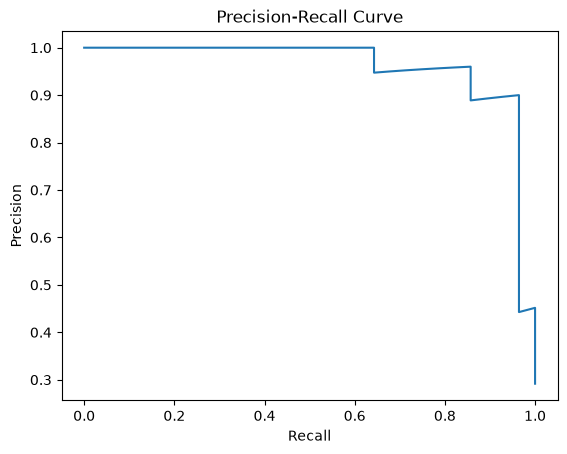

In [232]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt
precision, recall, thresholds = precision_recall_curve(
    y_train,
    yes_proba_cv,
    pos_label='Yes'
)
plt.plot(recall, precision)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.show()

In [233]:
from sklearn.metrics import average_precision_score
ap = average_precision_score(
    y_train,
    yes_proba_cv,
    pos_label='Yes'
)
print('Average Precision:', ap)

Average Precision: 0.9597429732003948


In [234]:
best_f1 = 0
best_threshold = 0

for i in range(len(thresholds)):
    pr = precision[i]
    re = recall[i]
    f1 = 2 * (pr*re/(pr+re))
    if f1>best_f1:
        best_f1 = f1
        best_threshold = thresholds[i]
print(best_f1)
print(best_threshold)

0.9310344827586207
0.3317678571428571


In [235]:
test_proba = best_rf.predict_proba(X_test)[:, 1]
final_pred = [
    'Yes' if prob >= best_threshold else 'No'
    for prob in test_proba
]
print('Accuracy:', accuracy_score(y_test, final_pred))
print('Precision:', precision_score(y_test, final_pred, pos_label='Yes'))
print('Recall:', recall_score(y_test, final_pred, pos_label='Yes'))
print('F1:', f1_score(y_test, final_pred, pos_label='Yes'))

print(
    confusion_matrix(
        y_test,
        final_pred,
        labels=['No', 'Yes']
    )
)

Accuracy: 0.9166666666666666
Precision: 0.8571428571428571
Recall: 0.8571428571428571
F1: 0.8571428571428571
[[16  1]
 [ 1  6]]


In [236]:
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt

test_proba = best_rf.predict_proba(X_test)[:, 1]

auc = roc_auc_score(
    y_test,
    test_proba
)

print("ROC-AUC:", auc)

ROC-AUC: 0.9159663865546218


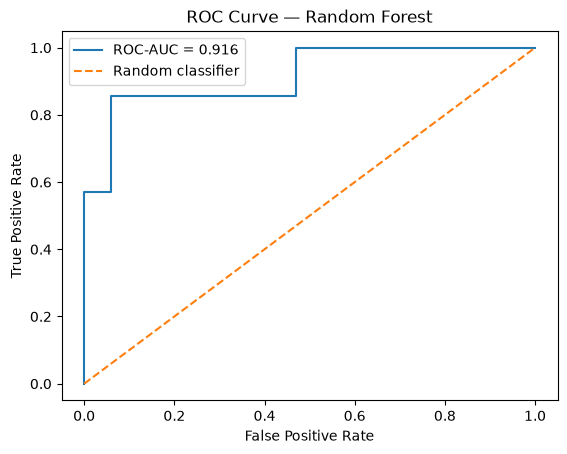

In [237]:
fpr, tpr, thresholds = roc_curve(
    y_test,
    test_proba,
    pos_label="Yes"
)

plt.plot(fpr, tpr, label=f"ROC-AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], "--", label="Random classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Random Forest")
plt.legend()
plt.show()

In [238]:
errors = X_test.copy()
errors['actual'] = y_test
errors['predicted'] = final_pred
errors['churn_probability'] = test_proba
errors = errors[
    errors['actual'] != errors['predicted']
    ]
print(errors)

     gender  senior_citizen partner dependents phone_service multiple_lines  \
107  Female               0     Yes         No           Yes            Yes   
0      Male               0     Yes         No           Yes             No   

    internet_service online_security online_backup device_protection  \
107              DSL             Yes            No               Yes   
0                DSL              No           Yes                No   

           contract  monthly_charges actual predicted  churn_probability  
107  Month-to-month            69.60     No       Yes           0.902878  
0    Month-to-month            29.85    Yes        No           0.107083  


In [239]:
feature_names = best_rf.named_steps['preprocessor'].get_feature_names_out()
print(feature_names)

['cat__gender_Female' 'cat__gender_Male' 'cat__senior_citizen_0'
 'cat__senior_citizen_1' 'cat__partner_No' 'cat__partner_Yes'
 'cat__dependents_No' 'cat__dependents_Yes' 'cat__phone_service_No'
 'cat__phone_service_Yes' 'cat__multiple_lines_No'
 'cat__multiple_lines_Yes' 'cat__internet_service_DSL'
 'cat__internet_service_Fiber optic' 'cat__internet_service_No'
 'cat__online_security_No' 'cat__online_security_Yes'
 'cat__online_backup_No' 'cat__online_backup_Yes'
 'cat__device_protection_No' 'cat__device_protection_Yes'
 'cat__contract_Month-to-month' 'cat__contract_One year'
 'cat__contract_Two year' 'num__monthly_charges']


In [240]:
importances = best_rf.named_steps['model'].feature_importances_
print(importances)

[0.00716032 0.00488743 0.02474439 0.02967554 0.024754   0.0257247
 0.05348755 0.04804714 0.02457377 0.02591716 0.03528048 0.03632973
 0.03098773 0.02481362 0.00776487 0.03617213 0.01716426 0.04719365
 0.05522726 0.04929758 0.04143142 0.07712632 0.03949213 0.04064161
 0.1921052 ]


In [241]:
feature_pd = pd.Series(data=importances, index=feature_names).sort_values(ascending=False)
print(feature_pd.head(10))

num__monthly_charges            0.192105
cat__contract_Month-to-month    0.077126
cat__online_backup_Yes          0.055227
cat__dependents_No              0.053488
cat__device_protection_No       0.049298
cat__dependents_Yes             0.048047
cat__online_backup_No           0.047194
cat__device_protection_Yes      0.041431
cat__contract_Two year          0.040642
cat__contract_One year          0.039492
dtype: float64


In [242]:
from sklearn.inspection import permutation_importance

result = permutation_importance(
    best_rf,
    X_train,
    y_train,
    scoring=f1_scorer,
    n_repeats=10,
    random_state=42
)
result_pd = pd.Series(data=result.importances_mean, index=X_train.columns).sort_values(ascending=False)
print(result_pd.head(10))

monthly_charges      0.248319
contract             0.115871
online_backup        0.101760
dependents           0.100404
senior_citizen       0.036902
multiple_lines       0.031178
phone_service        0.025791
online_security      0.016364
device_protection    0.012343
internet_service     0.010909
dtype: float64


In [243]:
import joblib

model_artifact = {
    'pipeline': best_rf,
    'threshold': float(best_threshold),
    'positive_class': 'Yes'

}
joblib.dump(model_artifact, '../models/churn_model.joblib')
loaded_artifact = joblib.load('../models/churn_model.joblib')
print(loaded_artifact.keys())
print(loaded_artifact['threshold'])

dict_keys(['pipeline', 'threshold', 'positive_class'])
0.3317678571428571
